In [2]:
import numpy as np
import pandas as pd
from data_loader import *
from torchvision import transforms
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Estrutura dos dados:

### Formato dos labels

In [3]:
root = "../pa3_dados"

In [4]:
dim_classes = pd.read_csv(f"{root}/classes.csv")

In [5]:
dim_classes

,idx,label
0,0,american_black_bear
1,1,american_crow
2,2,bird
3,3,bobcat
4,4,chicken
5,5,coyote
6,6,dog
7,7,domestic_cat
8,8,eastern_chipmunk
9,9,eastern_cottontail


In [6]:
y_train = get_labels(root, labels_qtt=5)
y_val   = get_labels(root, file_name="val")
y_test  = get_labels(root, file_name="test_public")


y_train_map = {
    k: v["label"]
    for k, v in y_train.set_index("image_id").to_dict(orient="index").items()
}

y_val_map = {
    k: v["label"]
    for k, v in y_val.set_index("image_id").to_dict(orient="index").items()
}

y_test_map = {
    k: v["label"]
    for k, v in y_test.set_index("image_id").to_dict(orient="index").items()
}

In [7]:
y_train

,image_id,label
0,64e6f65bcf6e4dcf,american_black_bear
1,41f2d0b18bb10009,american_black_bear
2,195096716dfeff12,american_black_bear
3,6e989bf81dd47de1,american_black_bear
4,5ca7fcbe37f3af1c,american_black_bear
...,...,...
100,00e95d49dd18314e,woodchuck
101,dd9aabcaa15993df,woodchuck
102,58cc32cde05d0e62,woodchuck
103,d911728be6d4fbcb,woodchuck


In [8]:
y_train_labels_qtt = y_train.groupby("label").count().rename(columns={"image_id": "QTT_TRAIN"}).reset_index()
y_val_labels_qtt   = y_val.groupby("label").count().rename(columns={"image_id": "QTT_VAL"}).reset_index()
y_test_labels_qtt  = y_test.groupby("label").count().rename(columns={"image_id": "QTT_TEST"}).reset_index()

(
    y_train_labels_qtt
    .merge(
        y_val_labels_qtt,
        on="label",
        how="outer"
    )
    .merge(
        y_test_labels_qtt,
        on="label",
        how="outer"
    )
)

,label,QTT_TRAIN,QTT_VAL,QTT_TEST
0,american_black_bear,5,10,82
1,american_crow,5,10,63
2,bird,5,10,22
3,bobcat,5,10,34
4,chicken,5,10,60
5,coyote,5,10,31
6,dog,5,10,67
7,domestic_cat,5,10,48
8,eastern_chipmunk,5,10,31
9,eastern_cottontail,5,10,26


### Formato das imagens

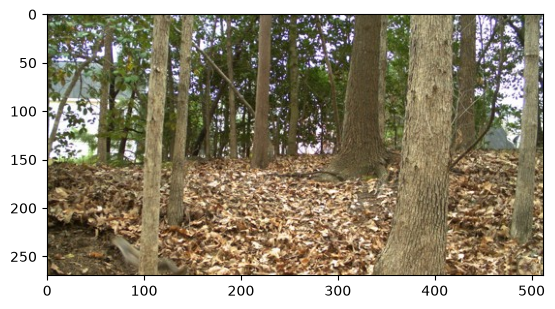

In [9]:
transform_unsupervised = transforms.Compose([
    transforms.ToTensor(),
])

# Instancia o Dataset
train_dataset = ENA24UnsupervisedDataset(
    root_dir='../pa3_dados', 
    split='train', 
    transform=transform_unsupervised
)

# Cria o DataLoader
train_loader = DataLoader(
    train_dataset, 
    batch_size=1, 
    shuffle=True,  # Para treino, embaralhamos os dados
    num_workers=2
)

# Testando um batch
shapes = []
for images, _ in train_loader:
    shapes.append(images.shape[-2:])


image = images[0].numpy().transpose((1, 2, 0))

image = np.clip(image, 0, 1)
plt.imshow(image)

In [10]:
df_shapes = pd.DataFrame(shapes, columns=["height", "width"])

In [11]:
print("Alturas:", sorted(df_shapes["height"].unique().tolist()))
print("Larguras:", sorted(df_shapes["width"].unique().tolist()))

Alturas: [270, 359, 364, 367, 368]
Larguras: [512]


In [12]:
df_shapes.groupby("height").count().rename(columns={"width": "QTD"}).reset_index()

,height,QTD
0,270,2457
1,359,817
2,364,204
3,367,3018
4,368,9


In [13]:
df_shapes.describe()[["height"]].round(2)

,height
count,6505.00
mean,329.26
std,46.24
min,270.00
25%,270.00
50%,359.00
75%,367.00
max,368.00
